# **Klasifikasi Deteksi Status Kantuk Menggunakan SVM**


## **1.0 Busines Understanding**

### **1.1 Latar Belakang**
Sebuah lembaga ingin membangun sistem untuk mendeteksi tingkat kelelahan dan status kantuk pengemudi secara otomatis.

### **1.2 Tujuan**
Tujuannya yaitu untuk membangun model machine learning untuk mendeteksi tingkat kelelahan dan status kantuk secara otomatis.


### **1.3 Masalah**
Dalam proses observasi, masih dilakukan dengan cara manual sehingga membutuhkan waktu yang lama dalam proses observasi.

### **1.4 Solusi**
Solusinya yaitu membangun model machine learning berbasis SVM untuk mendeteksi tingkat kelelahan dari gelombang otak dan  biologis mata.

### **1.5 Dataset**

**Ukuran Data: 1000 baris (mewakili 1000 sampel rekaman sensor) dan 3 kolom**

**Fitur Input (X): Kolom atribut pengukuran fisiologis, yang meliputi:**
- Tingkat Theta: Aktivitas gelombang otak theta (Theta wave power) yang
berkaitan dengan kondisi relaksasi dan kantuk (satuan: μV ).
2
- Indeks Kedipan Mata: Frekuensi dan durasi rata-rata kedipan kelopak mata
(Eye blink index) per menit.

**Target Label (Y): Kolom Status Kantuk di bagian akhir yang berisi data kategori (string / biner):**
- "Tidak Mengantuk" (Kondisi waspada / terjaga).
- "Mengantuk" (Kondisi kelelahan / penurunan konsentrasi).

## **2.0 Data Preparation**


In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tkinter as tk
from tkinter import ttk

In [89]:
# df = pd.read_csv('mengantuk.csv')
df = pd.read_csv('../dataset/mengantuk.csv')
df.head(10)

,Tingkat Theta,Indeks Kedipan Mata,Status Kantuk
0,4.16,21.75,Tidak Mengantuk
1,13.00,15.87,Mengantuk
2,7.45,14.09,Mengantuk
3,10.69,15.83,Mengantuk
4,9.28,23.36,Mengantuk
5,11.59,17.98,Mengantuk
6,10.81,16.02,Mengantuk
7,2.88,25.43,Tidak Mengantuk
8,7.70,14.21,Mengantuk
9,2.42,27.60,Tidak Mengantuk


In [90]:
df.info()
df.size

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Tingkat Theta        1000 non-null   float64
 1   Indeks Kedipan Mata  1000 non-null   float64
 2   Status Kantuk        1000 non-null   str    
dtypes: float64(2), str(1)
memory usage: 23.6 KB


3000

dataset ini memiliki 3 kolom yang terdiri dari 2 fitur input dan 1 target label. Dimana tipe datanya adalah numerik (float) dan string. Dataset ini memiliki 3000 framesize

In [91]:
df.isna().sum()

Tingkat Theta          0
Indeks Kedipan Mata    0
Status Kantuk          0
dtype: int64

In [92]:
df.duplicated().sum()

np.int64(0)

Dataset ini cenderung bersih karena tidak memiliki missing value dan data yang duplikat


## **3.0 Exploratory Data Analysis**

In [93]:
df.describe()

,Tingkat Theta,Indeks Kedipan Mata
count,1000.000000,1000.000000
mean,6.126480,20.604060
std,4.107107,4.025573
min,-3.990000,11.090000
25%,2.530000,17.145000
50%,6.205000,20.780000
75%,9.730000,24.070000
max,14.930000,31.720000


Dari desribe diatas terlihat pada min tingkat theta terdapat nilai yang minus sehingga nantinya di modeling akan di standarisasi supaya untuk menghilangkan nilai yang minus.

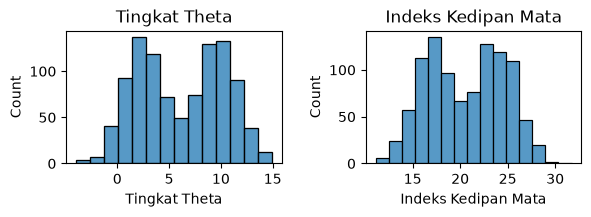

In [94]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(cols, start=1):
    plt.subplot(5, 5, i)
    sns.histplot(df[col])
    plt.title(col)

plt.tight_layout(h_pad=2, w_pad=2)
plt.show()

Pada distribusi data ini terlihat karakteristik termasuk bimodal dimana datanya ini terdapat 2 puncak data.

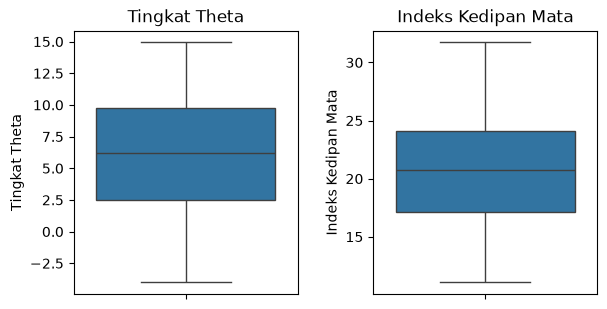

In [95]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(15, 15))

for i, col in enumerate(cols, start=1):
    plt.subplot(5, 5, i)
    sns.boxplot(df[col])
    plt.title(col)

plt.tight_layout(h_pad=2, w_pad=2)
plt.show()

Dari segi boxplot tidak ada indikasi outlier, namun nantinya akan dicek ulang menggunakan IQR.

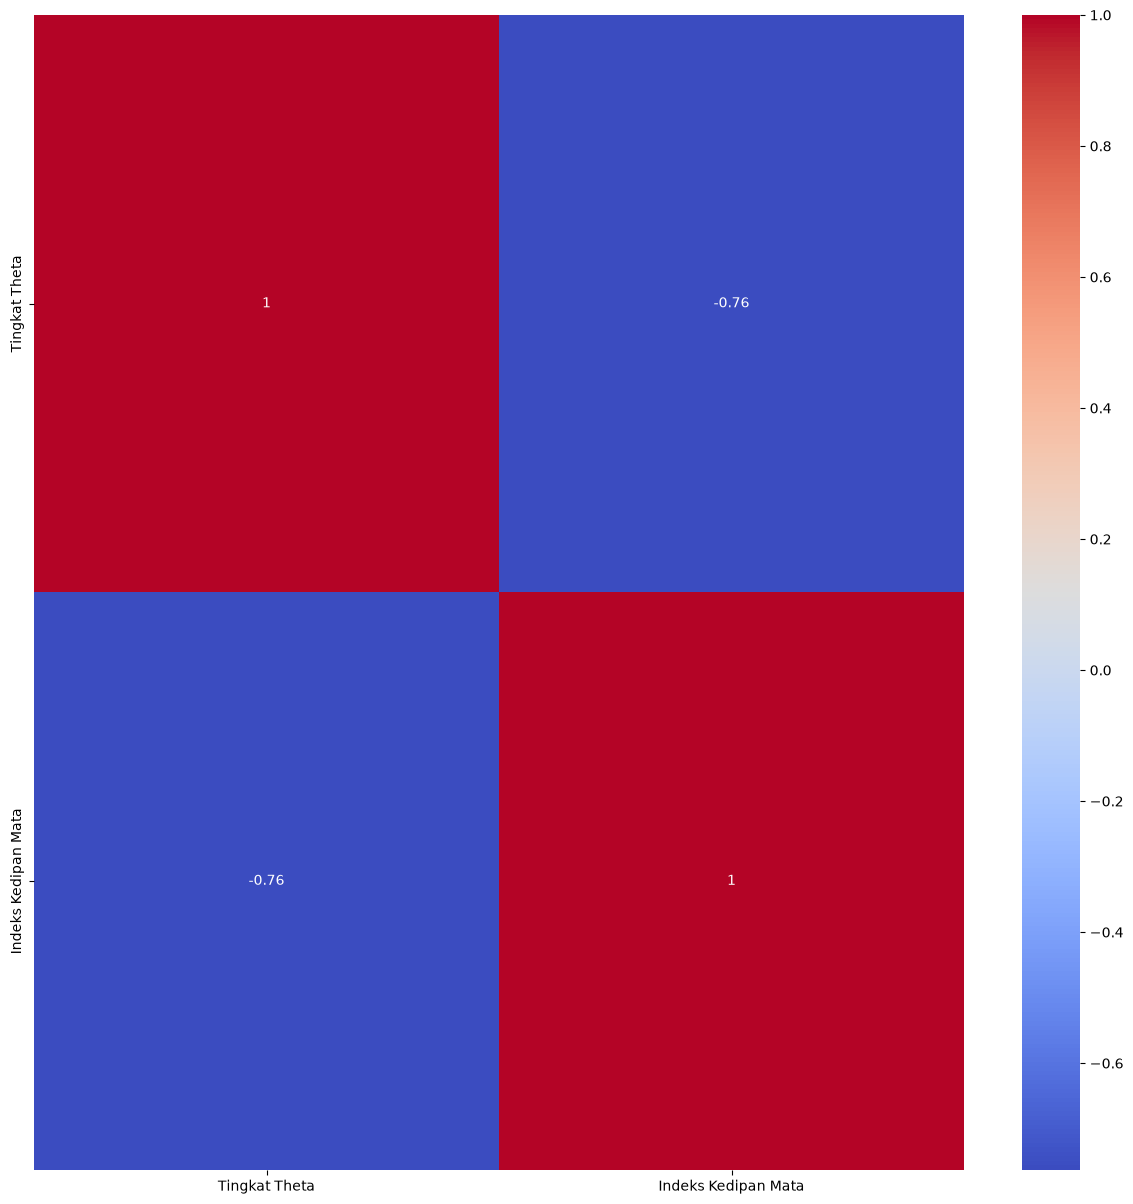

In [96]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(15, 15))
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm')
plt.show()


dari korelasi data di atas terlihat tingkat theta dan indeks kedipan mata memiliki korelasi -0.76 sehinnga distribusi datanya akan turun kebawah

## **4.0 Data Pre-Procesing**

In [97]:
q1 = df[cols].quantile(0.25)
q3 = df[cols].quantile(0.75)

iqr = q3 - q1

bb = q1 - 1.5 * iqr
bt = q3 + 1.5 * iqr

outlier = ((df[cols] < bb) | (df[cols] > bt)).sum()

hasil = pd.DataFrame({'Outlier': outlier, 'Persentase': outlier / len(df[cols])})
hasil.sort_values(by='Outlier', ascending=False)


,Outlier,Persentase
Tingkat Theta,0,0.0
Indeks Kedipan Mata,0,0.0


dari pengecekkan outlier menggunakan iqr tidak ada indikasi outlier sehingga data ini tidak ada handling outlier dan termasuk tegolong bersih.

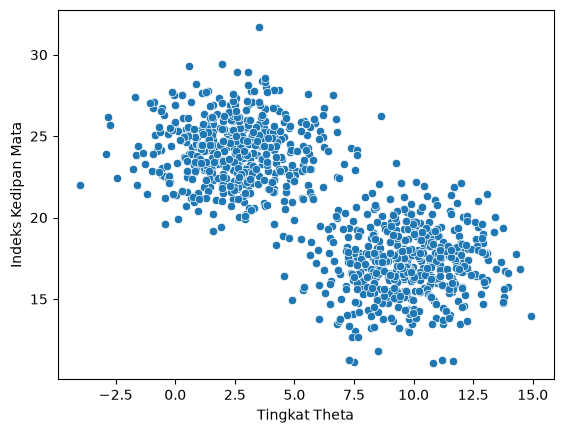

In [98]:
sns.scatterplot(x='Tingkat Theta', y='Indeks Kedipan Mata', data=df)
plt.show()


Jika dilihat dari heatmap tadi maka scatterplot ini sudah bisa menggambarkan jika korelasinya minus akan distribusinya kebawah dan jika dilihat sudah ada pengelompokkan data.

In [99]:
df['Status Kantuk'] = df['Status Kantuk'].map({'Tidak Mengantuk': -1, 'Mengantuk': 1}) 

In [100]:
df.head(10)

,Tingkat Theta,Indeks Kedipan Mata,Status Kantuk
0,4.16,21.75,-1
1,13.00,15.87,1
2,7.45,14.09,1
3,10.69,15.83,1
4,9.28,23.36,1
5,11.59,17.98,1
6,10.81,16.02,1
7,2.88,25.43,-1
8,7.70,14.21,1
9,2.42,27.60,-1


Saya melakukan encoding pada status kantuk dengan -1 dan 1 karena status kantuk itu tipe datanya string maka harus dirubah.

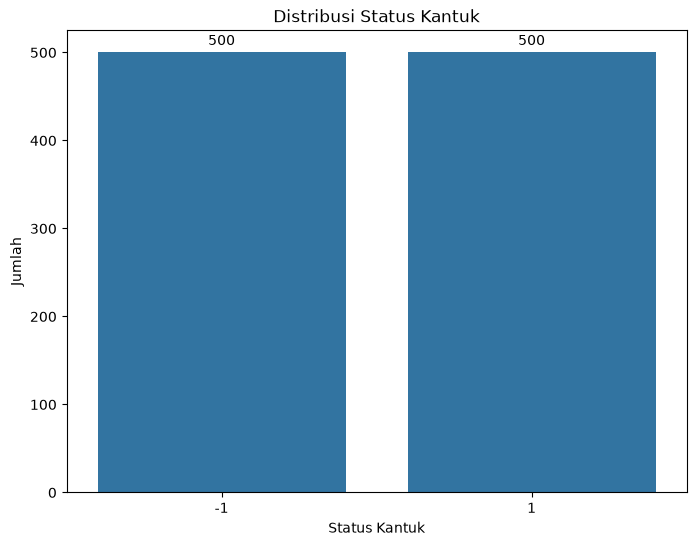

In [101]:
plt.figure(figsize=(8, 6))

ax = sns.countplot(x=df['Status Kantuk'])

plt.title('Distribusi Status Kantuk')
plt.xlabel('Status Kantuk')
plt.ylabel('Jumlah')

for container in ax.containers:
    ax.bar_label(container, padding=3)
    

plt.show()

Kemudian saya cek distribusi datanya terlihat distribusi datanya ini termasuk balance karena dari status kantuk dan tidak kantuk terlihat jumlah datanya sama sama 500 data.

In [102]:
X = df.drop(columns=['Status Kantuk'])
y = df['Status Kantuk']

In [103]:
def split_data (X,y,train_size= 0.8, random_state = 67):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    split_ratio = int(train_size * len(X))
    
    X_train,X_test = X.iloc[idx[:split_ratio]] , X.iloc[idx[split_ratio:]]
    y_train,y_test = y.iloc[idx[:split_ratio]] , y.iloc[idx[split_ratio:]] 
    
    return X_train,X_test,y_train,y_test

X_train,X_test,y_train,y_test = split_data(X,y)

## **5.0 Modeling**

In [104]:
class SVM:
    def __init__(self,lr=0.01,lam=0.01, iter=100):
        self.lr = lr
        self.lam = lam
        self.iter = iter
        
    def fit(self,X,y):
        X = np.asarray(X)
        # self.min, self.max = X.min(0), X.max(0)
        # X = (X - self.min) / (self.max - self.min) + 1e-8
        self.mean, self.std = X.mean(0), X.std(0) + 1e-8
        X = (X - self.mean) / self.std
        
        y_ = np.where(np.asarray(y).ravel() == 1, 1, -1)
        self.w, self.b = np.zeros(X.shape[1]), 0.0
        
        for _ in range(self.iter):
            mask = y_ * (X @ self.w + self.b) < 1
            self.w -= self.lr * (2 * self.lam * self.w - (mask * y_) @ X / len(X))
            self.b += self.lr * np.mean(mask * y_)
        return self
    
    def predict(self, X):
        X = (np.asarray(X) - self.mean) / self.std
        # X = (np.asarray(X) - self.min) / (self.max - self.min) + 1e-8
        return np.where(X @ self.w + self.b >= 0, 1, -1)

## **6.0 Evaluasi**

In [105]:
X_tr, X_val, y_tr, y_val = split_data(X_train,y_train,train_size=0.8, random_state=67)

print(f"hasil split X train: {len(X_tr)}")
print(f"hasil split X val: {len(X_val)}")

print(f"hasil split y train: {len(y_tr)}")
print(f"hasil split y val: {len(y_val)}")


hasil split X train: 640
hasil split X val: 160
hasil split y train: 640
hasil split y val: 160


In [106]:
model = SVM(lr=0.1, lam=0.01, iter=500)
model.fit(X_train,y_train)
y_pred = model.predict(X_val)
akurasi = np.mean(y_pred == y_val) * 100
print(akurasi)


98.75


In [107]:
import itertools

def grid_search(model_cls, param_grid, X_tr,y_tr,X_val,y_val):
    keys = list(param_grid.keys())
    best_score, best_params = -np.inf, None
    
    for vals in itertools.product(*param_grid.values()):
        params = dict(zip(keys, vals))
        
        model = model_cls(**params)
        model.fit(X_tr,y_tr)
        
        preds = model.predict(X_val)
        score = np.mean(preds == y_val)
        
        if score > best_score:
            best_score, best_params = score, params
    
    return best_params, best_score

In [108]:
param_grid = {
    'lr':[0.01, 0.05, 0.1],
    'lam':[0.001,0.01,0.1],
    'iter':[200,300,500],
}

best_p, best_s = grid_search(SVM, param_grid, X_tr,y_tr,X_val,y_val)
print(f"Parameter terbaik: {best_p}")
print(f"akurasi terbaik: {best_s * 100}")

Parameter terbaik: {'lr': 0.01, 'lam': 0.001, 'iter': 200}
akurasi terbaik: 99.375


In [109]:
X_train = pd.concat([X_tr,X_val])
y_train = pd.concat([y_tr,y_val])


In [110]:
model_terbaik = SVM(**best_p)
model_terbaik.fit(X_train,y_train)
y_pred = model_terbaik.predict(X_test)


In [111]:
y_true = y_test

TP = np.sum((y_true == 1) & (y_pred == 1))
TN = np.sum((y_true == -1) & (y_pred == -1))
FP = np.sum((y_true == -1) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == -1))

akurasi = np.mean(y_pred == y_true) * 100
presisi = (TP / (TP + FP)) * 100 if (TP + FP) > 0 else 0
recall = (TP / (TP + FN)) * 100 if (TP + FN) > 0 else 0
f1 = (2 * presisi * recall) / (presisi + recall) if (presisi + recall) > 0 else 0

print(f"Akurasi : {akurasi:}")
print(f"Precision : {presisi:}")
print(f"Recall    : {recall:}")
print(f"F1-Score  : {f1:}")

Akurasi : 99.5
Precision : 100.0
Recall    : 98.9795918367347
F1-Score  : 99.48717948717947


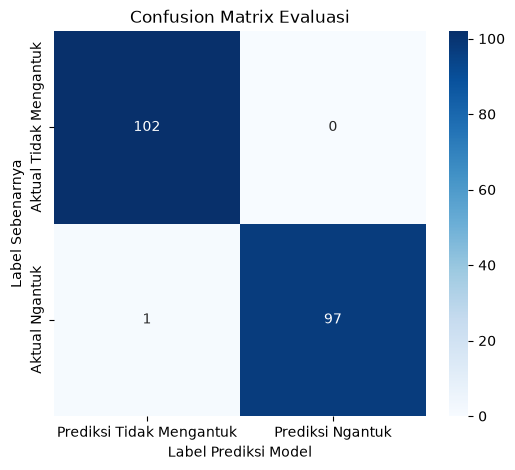

In [112]:
cm = np.array([[TN,FP] , [FN,TP]])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=['Prediksi Tidak Mengantuk', 'Prediksi Ngantuk'],
    yticklabels=['Aktual Tidak Mengantuk', 'Aktual Ngantuk']
)
plt.title('Confusion Matrix Evaluasi', fontsize=12)
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi Model')
plt.show()

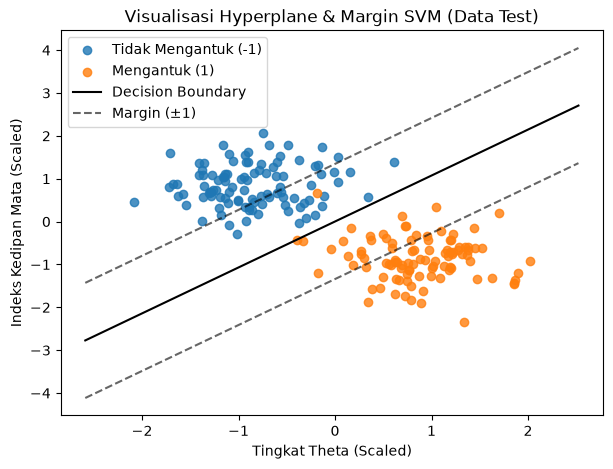

In [113]:
X_sc = (np.asarray(X_test) - model_terbaik.mean) / model_terbaik.std
w, b = model_terbaik.w, model_terbaik.b

x_vals = np.linspace(X_sc[:, 0].min() - 0.5, X_sc[:, 0].max() + 0.5, 100)
y_boundary = -(w[0] * x_vals + b) / w[1]
y_margin_pos = -(w[0] * x_vals + b - 1) / w[1]
y_margin_neg = -(w[0] * x_vals + b + 1) / w[1]

plt.figure(figsize=(7, 5))
plt.scatter(X_sc[y_test == -1, 0], X_sc[y_test == -1, 1], label='Tidak Mengantuk (-1)', alpha=0.8)
plt.scatter(X_sc[y_test == 1, 0], X_sc[y_test == 1, 1], label='Mengantuk (1)', alpha=0.8)
plt.plot(x_vals, y_boundary, 'k-', label='Decision Boundary')
plt.plot(x_vals, y_margin_pos, 'k--', alpha=0.6, label='Margin (±1)')
plt.plot(x_vals, y_margin_neg, 'k--', alpha=0.6)
plt.xlabel('Tingkat Theta (Scaled)')
plt.ylabel('Indeks Kedipan Mata (Scaled)')
plt.title('Visualisasi Hyperplane & Margin SVM (Data Test)')
plt.legend()
plt.show()

In [ ]:
KONFIGURASI = {
    "Tingkat Theta": {
        "label": "Aktivitas gelombang otak theta",
        "type": "number",
        "default": 10,
    },
    "Indeks Kedipan Mata": {
        "label": "Indeks kedipan mata",
        "type": "number",
        "default": 5,
    },
}

LABEL = {-1: "Tidak Mengantuk", 1: "Mengantuk"}

WARNA = {
    1: ("#f8d7da", "#a12622"),    # Mengantuk -> latar merah
    -1: ("#d9ead3", "#1e6b34"),   # Tidak Mengantuk -> latar hijau
}

FITUR = list(KONFIGURASI.keys())

if 'df' not in dir() or 'model_terbaik' not in dir():
    raise NameError(
        "Jalankan cell-cell di atas sampai proses modeling selesai, "
        "barulah jalankan cell GUI ini."
    )

def prediksi(data):
    # Model SVM sudah menstandarkan input dengan mean/std dari data training
    X = np.array([[data[kolom] for kolom in FITUR]], dtype=float)
    return int(model_terbaik.predict(X)[0])

def format_profil(data, hasil):
    baris = "\n".join(
        "  {:<32}: {:g}".format(KONFIGURASI[kolom]["label"], data[kolom])
        for kolom in FITUR
    )
    return "Status : {}\n\nRincian input:\n{}".format(LABEL[hasil], baris)


class Aplikasi(tk.Tk):
    def __init__(self):
        super().__init__()
        self.title("Aplikasi Deteksi Status Kantuk (SVM)")
        self.geometry("580x620")
        self.resizable(False, False)
        
        self.entries = {}
        self._build_form()
        self._pesan('Isi indikatornya, lalu tekan "Prediksi".')

    def _build_form(self):
        header = tk.Frame(self, bg="#1f4e79", height=75)
        header.pack(fill="x")

        tk.Label(header, text="Deteksi Status Kantuk", font=("Segoe UI", 16, "bold"), fg="#fff", bg="#1f4e79").pack(pady=(12, 0))
        tk.Label(header, text="SVM (Support Vector Machine)", font=("Segoe UI", 10), fg="#fff", bg="#1f4e79").pack()

        self._build_result()

        container = ttk.Frame(self)
        container.pack(fill="both", expand=True, padx=20, pady=15)

        self.form = ttk.Frame(container, padding=10)
        self.form.pack(fill="both", expand=True)
        self.form.columnconfigure(1, weight=1)

        self._build_inputs()
        self._build_buttons()

    
    def _build_result(self):
        self.hasil_var = tk.StringVar(value="Hasil prediksi")

        self.result_frame = tk.Frame(self, bg="#eaf2f8", padx=14, pady=12)
        self.result_frame.pack(side="bottom", fill="x", padx=20, pady=(0, 15))

        self.hasil_label = tk.Label(
            self.result_frame, textvariable=self.hasil_var,
            font=("Segoe UI", 16, "bold"),
            bg="#eaf2f8", fg="#1f4e79", anchor="w", wraplength=520)
        self.hasil_label.pack(fill="x", pady=(0, 8))

        self.result_text = tk.Text(
            self.result_frame, height=12, wrap="word",
            font=("Consolas", 9), bg="#eaf2f8", fg="#333333",
            relief="flat", state="disabled")
        self.result_text.pack(fill="both", expand=True)
    
    def _build_inputs(self):
        # Baris 0..n: fitur numerik
        for r, (kolom, config) in enumerate(KONFIGURASI.items()):
            ttk.Label(self.form, text=config["label"],
                      font=("Segoe UI", 10)).grid(
                row=r, column=0, sticky="w", padx=(0, 12), pady=8)

            widget = ttk.Entry(self.form, font=("Segoe UI", 10))
            widget.insert(0, str(config["default"]))
            widget.grid(row=r, column=1, sticky="ew", pady=8)
            self.entries[kolom] = widget

    def _build_buttons(self):
        tombol = ttk.Frame(self.form)
        tombol.grid(row=len(KONFIGURASI), column=0, columnspan=2,
                    sticky="ew", pady=20)

        daftar_tombol = [
            ("Isi Otomatis", self.on_autofill),
            ("Prediksi Otomatis", self.on_auto),
            ("Prediksi", self.on_predict),
            ("Reset", self.on_reset),
        ]

        for kolom in range(len(daftar_tombol)):
            tombol.columnconfigure(kolom, weight=1)

        for kolom, (label, aksi) in enumerate(daftar_tombol):
            ttk.Button(tombol, text=label, command=aksi).grid(
                row=0, column=kolom, sticky="ew", padx=5, ipady=6)

    # --------------------------------------------------------
    def _pesan(self, teks, bg="#f2f2f2", fg="#333333"):
        self.result_text.configure(state="normal")
        self.result_text.delete("1.0", tk.END)
        self.result_text.insert("1.0", teks)
        self.result_text.configure(state="disabled", bg=bg, fg=fg)
        self.hasil_label.configure(bg=bg, fg=fg)
        self.result_frame.configure(bg=bg)

    # --------------------------------------------------------
    def _kumpulkan_input(self):
        data = {}
        for kolom, entry in self.entries.items():
            teks = entry.get().strip().replace(",", ".")
            if not teks:
                raise ValueError(
                    "{} tidak boleh kosong.".format(KONFIGURASI[kolom]["label"]))
            try:
                nilai = float(teks)
            except ValueError:
                raise ValueError(
                    "{} harus berupa angka.".format(KONFIGURASI[kolom]["label"]))
            if not np.isfinite(nilai):
                raise ValueError(
                    "{} tidak valid.".format(KONFIGURASI[kolom]["label"]))
            data[kolom] = nilai
        return data

    # --------------------------------------------------------
    def on_predict(self):
        try:
            data = self._kumpulkan_input()
            hasil = prediksi(data)
            bg, fg = WARNA[hasil]

            self.hasil_var.set("HASIL: {}".format(LABEL[hasil].upper()))
            self._pesan(format_profil(data, hasil), bg, fg)
        except ValueError as err:
            self.hasil_var.set("Periksa input")
            self._pesan("Input tidak valid: {}".format(err), "#f8d7da", "#a12622")

    # --------------------------------------------------------
    def _cari_contoh(self, target):
        """Cari satu baris dataset yang diprediksi sebagai kelas target."""
        data_semua = df[FITUR].to_numpy(dtype=float)
        for i in np.random.permutation(len(df)):
            baris = {kolom: float(data_semua[i, j])
                     for j, kolom in enumerate(FITUR)}
            if prediksi(baris) == target:
                return baris
        raise ValueError("contoh kelas {} tidak ditemukan.".format(LABEL[target]))

    # --------------------------------------------------------
    def on_auto(self):
        """Tampilkan sekaligus contoh Mengantuk dan Tidak Mengantuk."""
        try:
            contoh = {target: self._cari_contoh(target) for target in (1, -1)}

            # form diisi contoh yang mengantuk, supaya hasilnya bisa dicek ulang
            for kolom, entry in self.entries.items():
                entry.delete(0, tk.END)
                entry.insert(0, "{:.6g}".format(contoh[1][kolom]))

            bagian = [
                "CONTOH {} - PREDIKSI: {}\n{}".format(
                    no, LABEL[target].upper(), format_profil(contoh[target], target))
                for no, target in enumerate((1, -1), start=1)
            ]

            self.hasil_var.set("Prediksi otomatis: MENGANTUK & TIDAK MENGANTUK")
            self._pesan("\n\n".join(bagian), "#fdf3d7", "#7a5c00")
        except ValueError as err:
            self.hasil_var.set("Prediksi otomatis gagal")
            self._pesan("Prediksi otomatis gagal: {}".format(err),
                        "#f8d7da", "#a12622")

    # --------------------------------------------------------
    def on_autofill(self):
        pos = int(np.random.randint(len(df)))
        baris = df.iloc[pos]

        for kolom, entry in self.entries.items():
            entry.delete(0, tk.END)
            entry.insert(0, "{:.6g}".format(float(baris[kolom])))

        self.hasil_var.set("Data contoh siap")
        self._pesan("Data contoh berhasil diisi. Tekan Prediksi untuk melihat hasil.")

    # --------------------------------------------------------
    def on_reset(self):
        for kolom, entry in self.entries.items():
            entry.delete(0, tk.END)
            entry.insert(0, str(KONFIGURASI[kolom]["default"]))

        self.hasil_var.set("Hasil prediksi")
        self._pesan("Form berhasil direset. Silakan masukkan data.")

# ============================================================
# 8. MENJALANKAN APLIKASI
# ============================================================
app = Aplikasi()
app.mainloop()
